<a href="https://colab.research.google.com/github/drashtitech09/loan-approval-prediction/blob/main/Loan_approval_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Loan_approval prediction

In [129]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [130]:
df = pd.read_csv("/content/drive/MyDrive/AI ML/loan_data_new.csv")
print("Dataset loaded successfully")

Dataset loaded successfully


In [131]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  45000 non-null  int64  
 1   Gender               45000 non-null  object 
 2   Education            45000 non-null  object 
 3   Person Income        45000 non-null  int64  
 4   Employee Experience  45000 non-null  int64  
 5   Home Onwership       45000 non-null  object 
 6   Loan Amount          45000 non-null  int64  
 7   Loan Intent          45000 non-null  object 
 8   Loan interest Rate   45000 non-null  float64
 9   Loan percentage      45000 non-null  float64
 10  Credit History       45000 non-null  int64  
 11  Credit Score         45000 non-null  int64  
 12  Previous Loan        45000 non-null  object 
 13  Loan Status          45000 non-null  int64  
dtypes: float64(2), int64(7), object(5)
memory usage: 4.8+ MB


In [132]:
df

,Age,Gender,Education,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,female,Master,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,female,High School,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,male,Master,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27,male,Associate,47971,6,RENT,15000,MEDICAL,15.66,0.31,3,645,No,1
44996,37,female,Associate,65800,17,RENT,9000,HOMEIMPROVEMENT,14.07,0.14,11,621,No,1
44997,33,male,Associate,56942,7,RENT,2771,DEBTCONSOLIDATION,10.02,0.05,10,668,No,1
44998,29,male,Bachelor,33164,4,RENT,12000,EDUCATION,13.23,0.36,6,604,No,1


In [133]:
df.isna()

,Age,Gender,Education,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,False,False,False,False,False,False,False,False,False,False,False,False,False,False
44996,False,False,False,False,False,False,False,False,False,False,False,False,False,False
44997,False,False,False,False,False,False,False,False,False,False,False,False,False,False
44998,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [134]:
df.isna().sum()

,0
Age,0
Gender,0
Education,0
Person Income,0
Employee Experience,0
Home Onwership,0
Loan Amount,0
Loan Intent,0
Loan interest Rate,0
Loan percentage,0


In [135]:
print("duplicate rows: ",df.duplicated().sum())

duplicate rows:  0


In [136]:
if 'Education' in df.columns:
    df = df.drop('Education',axis=1)

In [137]:
if 'Loan Intent' in df.columns:
    df = df.drop('Loan Intent',axis=1)

In [138]:
df

,Age,Gender,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,female,71948,0,RENT,35000,16.02,0.49,3,561,No,1
1,21,female,12282,0,OWN,1000,11.14,0.08,2,504,Yes,0
2,25,female,12438,3,MORTGAGE,5500,12.87,0.44,3,635,No,1
3,23,female,79753,0,RENT,35000,15.23,0.44,2,675,No,1
4,24,male,66135,1,RENT,35000,14.27,0.53,4,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27,male,47971,6,RENT,15000,15.66,0.31,3,645,No,1
44996,37,female,65800,17,RENT,9000,14.07,0.14,11,621,No,1
44997,33,male,56942,7,RENT,2771,10.02,0.05,10,668,No,1
44998,29,male,33164,4,RENT,12000,13.23,0.36,6,604,No,1


In [139]:
df = pd.read_csv('/content/drive/MyDrive/AI ML/loan_data_new.csv')

In [140]:
print(df['Gender'].unique())

['female' 'male']


In [141]:
df['Gender'] =df['Gender'].map({'male':0 , 'female':1})

In [142]:
df

,Age,Gender,Education,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,1,Master,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,1,High School,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,1,High School,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,1,Bachelor,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,0,Master,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27,0,Associate,47971,6,RENT,15000,MEDICAL,15.66,0.31,3,645,No,1
44996,37,1,Associate,65800,17,RENT,9000,HOMEIMPROVEMENT,14.07,0.14,11,621,No,1
44997,33,0,Associate,56942,7,RENT,2771,DEBTCONSOLIDATION,10.02,0.05,10,668,No,1
44998,29,0,Bachelor,33164,4,RENT,12000,EDUCATION,13.23,0.36,6,604,No,1


In [143]:
df['Home Onwership'] = df['Home Onwership'].map({'RENT': 0, 'OWN': 1, 'MORTGAGE': 2})

In [144]:
df

,Age,Gender,Education,Person Income,Employee Experience,Home Onwership,Loan Amount,Loan Intent,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,1,Master,71948,0,0.0,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,1,High School,12282,0,1.0,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,1,High School,12438,3,2.0,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,1,Bachelor,79753,0,0.0,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,0,Master,66135,1,0.0,35000,MEDICAL,14.27,0.53,4,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44995,27,0,Associate,47971,6,0.0,15000,MEDICAL,15.66,0.31,3,645,No,1
44996,37,1,Associate,65800,17,0.0,9000,HOMEIMPROVEMENT,14.07,0.14,11,621,No,1
44997,33,0,Associate,56942,7,0.0,2771,DEBTCONSOLIDATION,10.02,0.05,10,668,No,1
44998,29,0,Bachelor,33164,4,0.0,12000,EDUCATION,13.23,0.36,6,604,No,1


In [145]:
if 'Education' in df.columns:
    df = df.drop('Education',axis=1)

In [146]:
if 'Loan Intent' in df.columns:
    df = df.drop('Loan Intent',axis=1)

In [147]:
if 'Home Onwership' in df.columns:
    df = df.drop('Home Onwership',axis=1)

In [148]:
df

,Age,Gender,Person Income,Employee Experience,Loan Amount,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,1,71948,0,35000,16.02,0.49,3,561,No,1
1,21,1,12282,0,1000,11.14,0.08,2,504,Yes,0
2,25,1,12438,3,5500,12.87,0.44,3,635,No,1
3,23,1,79753,0,35000,15.23,0.44,2,675,No,1
4,24,0,66135,1,35000,14.27,0.53,4,586,No,1
...,...,...,...,...,...,...,...,...,...,...,...
44995,27,0,47971,6,15000,15.66,0.31,3,645,No,1
44996,37,1,65800,17,9000,14.07,0.14,11,621,No,1
44997,33,0,56942,7,2771,10.02,0.05,10,668,No,1
44998,29,0,33164,4,12000,13.23,0.36,6,604,No,1


In [149]:
df['Previous Loan']=df['Previous Loan'].map({'Yes':1 , 'No':0})

In [150]:
df

,Age,Gender,Person Income,Employee Experience,Loan Amount,Loan interest Rate,Loan percentage,Credit History,Credit Score,Previous Loan,Loan Status
0,22,1,71948,0,35000,16.02,0.49,3,561,0,1
1,21,1,12282,0,1000,11.14,0.08,2,504,1,0
2,25,1,12438,3,5500,12.87,0.44,3,635,0,1
3,23,1,79753,0,35000,15.23,0.44,2,675,0,1
4,24,0,66135,1,35000,14.27,0.53,4,586,0,1
...,...,...,...,...,...,...,...,...,...,...,...
44995,27,0,47971,6,15000,15.66,0.31,3,645,0,1
44996,37,1,65800,17,9000,14.07,0.14,11,621,0,1
44997,33,0,56942,7,2771,10.02,0.05,10,668,0,1
44998,29,0,33164,4,12000,13.23,0.36,6,604,0,1


In [151]:
print(df.isnull().sum())

Age                    0
Gender                 0
Person Income          0
Employee Experience    0
Loan Amount            0
Loan interest Rate     0
Loan percentage        0
Credit History         0
Credit Score           0
Previous Loan          0
Loan Status            0
dtype: int64


In [152]:
#define input and output
x = df.drop('Loan Status',axis=1)
y = df['Loan Status']

In [153]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(x,y,test_size= 0.20 ,random_state=42 )
print("Training data:",X_train.shape)
print("Testing data: ",X_test.shape)

Training data: (36000, 10)
Testing data:  (9000, 10)


In [154]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [155]:
X_train_scaled

array([[0.11290323, 1.        , 0.01241039, ..., 0.25      , 0.52391304,
        0.        ],
       [0.04032258, 0.        , 0.00903032, ..., 0.07142857, 0.58478261,
        1.        ],
       [0.16935484, 1.        , 0.04373797, ..., 0.32142857, 0.63695652,
        1.        ],
       ...,
       [0.10483871, 1.        , 0.0069955 , ..., 0.25      , 0.56956522,
        1.        ],
       [0.0483871 , 0.        , 0.02371855, ..., 0.03571429, 0.46521739,
        0.        ],
       [0.0483871 , 1.        , 0.02820806, ..., 0.03571429, 0.59565217,
        1.        ]])

In [156]:
print(df.isnull().sum())

Age                    0
Gender                 0
Person Income          0
Employee Experience    0
Loan Amount            0
Loan interest Rate     0
Loan percentage        0
Credit History         0
Credit Score           0
Previous Loan          0
Loan Status            0
dtype: int64


In [157]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

LogisticRegression()

In [158]:
print("df NaN       :", df.isnull().sum().sum())
print("X_train NaN  :", X_train.isnull().sum().sum())
print("scaled NaN   :", np.isnan(X_train_scaled).sum())

df NaN       : 0
X_train NaN  : 0
scaled NaN   : 0


In [159]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression

In [160]:
X = df.drop('Loan Status', axis=1)
y = df['Loan Status']

In [161]:
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [162]:
print("X_train NaN:", X_train.isnull().sum().sum())
print("scaled NaN :", np.isnan(X_train_scaled).sum())


X_train NaN: 0
scaled NaN : 0


In [163]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression

# 1. split again from the clean df
X = df.drop('Loan Status', axis=1)
y = df['Loan Status']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 2. scale again
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. check, must be 0
print("df NaN     :", df.isnull().sum().sum())
print("X_train NaN:", X_train.isnull().sum().sum())
print("scaled NaN :", np.isnan(X_train_scaled).sum())

# 4. train
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
print("Model trained successfully")

df NaN     : 0
X_train NaN: 0
scaled NaN : 0
Model trained successfully


In [164]:
#model predection
y_pred = model.predict(X_test_scaled)

In [165]:
#compare actual value and predicted value
comparision = pd.DataFrame({
    "Actual Loan status" : y_test.values,
    "Predicted Loan status" : y_pred
})
comparision

,Actual Loan status,Predicted Loan status
0,0,0
1,0,0
2,0,0
3,0,0
4,1,0
...,...,...
8995,0,0
8996,0,0
8997,0,0
8998,0,0


In [166]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.8908888888888888

Confusion Matrix:
[[6567  433]
 [ 549 1451]]

              precision    recall  f1-score   support

           0       0.92      0.94      0.93      7000
           1       0.77      0.73      0.75      2000

    accuracy                           0.89      9000
   macro avg       0.85      0.83      0.84      9000
weighted avg       0.89      0.89      0.89      9000



In [167]:
train_score = model.score(X_train_scaled , y_train)
print("Train Accuracy-->",train_score * 100)

Train Accuracy--> 88.75277777777778


In [168]:
test_score = model.score(X_test_scaled,y_test)
print("Test Acuuracy-->",test_score * 100)

Test Acuuracy--> 89.08888888888889


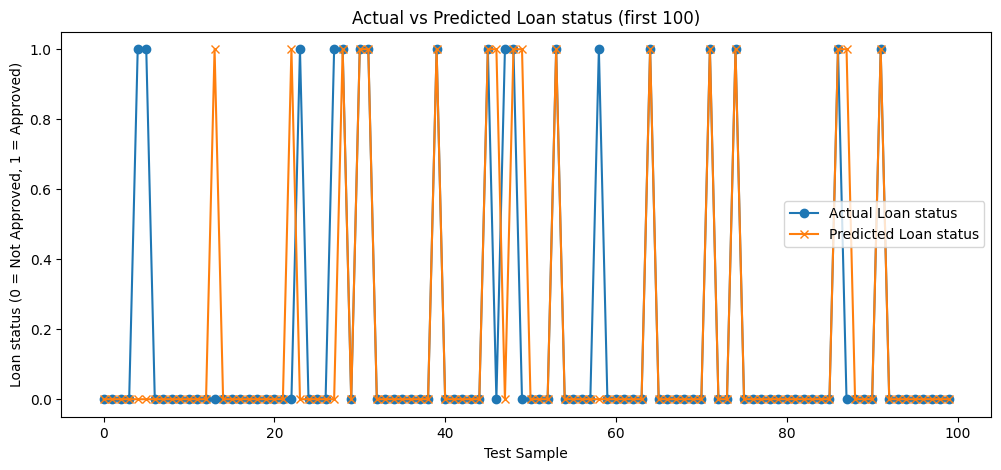

In [169]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values[:100], marker='o', label='Actual Loan status')
plt.plot(y_pred[:100], marker='x', label='Predicted Loan status')
plt.title('Actual vs Predicted Loan status (first 100)')
plt.xlabel('Test Sample')
plt.ylabel('Loan status (0 = Not Approved, 1 = Approved)')
plt.legend()
plt.show()

In [170]:
#compare 5 models and pick the best one.
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score
import pandas as pd

In [171]:
models = {
    "Logistic Regression": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "SVC": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

In [173]:
results = []
for name,model in models.items():
    #Train model
    model.fit(X_train_scaled , y_train)
    #Prediction
    y_pred = model.predict(X_test_scaled)
    #R2 Score
    r2 = model.score(X_test_scaled , y_test)
    results.append({
        "Model" : name,
        "Accuracy Score" : round(r2 ,2),
        "Accuracy Score(%)" : round(r2 *100 , 2)
    })
comparison = pd.DataFrame(results)
comparison

,Model,Accuracy Score,Accuracy Score(%)
0,Logistic Regression,0.89,89.09
1,KNN,0.89,88.99
2,SVC,0.90,90.13
3,Decision Tree,0.88,87.51
4,Random Forest,0.92,91.53


In [174]:
pip install gradio -q

In [175]:
from sklearn.ensemble import RandomForestClassifier

best_model = RandomForestClassifier(random_state=42)
best_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [179]:
import gradio as gr
import pandas as pd

def predict_loan(age, gender, income, experience, loan_amount,
                 interest_rate, loan_percent, credit_history,
                 credit_score, previous_loan):

    # 1. text to number (same as your encoding)
    gender_num = 0 if gender == "Male" else 1
    previous_loan_num = 1 if previous_loan == "Yes" else 0


    # 2. put inputs in the same order as X
    new_data = pd.DataFrame([[age, gender_num, income, experience,
                              loan_amount, interest_rate, loan_percent,
                              credit_history, credit_score,previous_loan_num]],
                            columns=X.columns)

    # 3. scale and predict
    new_scaled = scaler.transform(new_data)
    pred = best_model.predict(new_scaled)[0]
    prob = best_model.predict_proba(new_scaled)[0][1]

    # 4. number to words
    if pred == 1:
        return f"Loan Approved  (confidence: {prob*100:.1f}%)"
    else:
        return f"Loan Not Approved  (confidence: {(1-prob)*100:.1f}%)"

app = gr.Interface(
    fn=predict_loan,
    inputs=[
        gr.Number(label="Age"),
        gr.Radio(["Male", "Female"], label="Gender"),
        gr.Number(label="Person Income"),
        gr.Number(label="Employee Experience (years)"),
        gr.Number(label="Loan Amount"),
        gr.Number(label="Loan Interest Rate"),
        gr.Number(label="Loan Percentage (e.g. 0.25)"),
        gr.Number(label="Credit History(length in years)"),
        gr.Number(label="Credit Score"),
        gr.Radio(["Yes", "No"], label="Did the applicant take a loan before?"),
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Loan Approval Prediction"
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dd46866da62987fe56.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
